Clean Data

In [18]:
import pandas as pd
df = pd.read_csv("synthetic_hospital_data.csv")
df.head()

,patient_id,department,admission_datetime,discharge_datetime,waiting_time_min,admission_type
0,P0001,Internal Medicine,2026-03-31 08:00,2026-04-05 11:00,28.0,Routine
1,P0002,General Surgery,2026-03-11 10:00,2026-03-16 15:00,113.0,Routine
2,P0003,Emergency,2026-01-31 15:00,2026-02-02 16:00,166.0,Urgent
3,P0004,Internal Medicine,2026-01-07 21:00,2026-01-16 02:00,13.0,Urgent
4,P0005,General Surgery,2026-01-18 19:00,2026-01-24 22:00,144.0,Routine


In [38]:
df.shape

df.info()

df.describe()

df.isnull().sum()

df.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   patient_id          162 non-null    str    
 1   department          161 non-null    str    
 2   admission_datetime  162 non-null    str    
 3   discharge_datetime  161 non-null    str    
 4   waiting_time_min    160 non-null    float64
 5   admission_type      162 non-null    str    
dtypes: float64(1), str(5)
memory usage: 16.6 KB


np.int64(2)

In [39]:
df[df["waiting_time_min"] < 0]

,patient_id,department,admission_datetime,discharge_datetime,waiting_time_min,admission_type
76,P0077,Internal Medicine,2026-01-19 03:00,2026-01-27 09:00,-15.0,Routine


In [40]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

df_clean.loc[
    df_clean["waiting_time_min"]< 0,
    "waiting_time_min"
] = float("nan")

df_clean["admission_datetime"] = pd.to_datetime(df_clean["admission_datetime"])
df_clean["discharge_datetime"] = pd.to_datetime(df_clean["discharge_datetime"])

In [75]:
df_clean.info()
df_clean.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   patient_id           160 non-null    str           
 1   department           159 non-null    str           
 2   admission_datetime   160 non-null    datetime64[us]
 3   discharge_datetime   159 non-null    datetime64[us]
 4   waiting_time_min     157 non-null    float64       
 5   admission_type       160 non-null    str           
 6   length_of_stay_days  159 non-null    float64       
dtypes: datetime64[us](2), float64(2), str(3)
memory usage: 12.7 KB


patient_id             0
department             1
admission_datetime     0
discharge_datetime     1
waiting_time_min       3
admission_type         0
length_of_stay_days    1
dtype: int64

In [76]:
df_clean.to_csv("cleaned_hospital_data.csv", index=False)

KPI Calculation

In [33]:
df_clean.shape
df_clean.dtypes

patient_id                       str
department                       str
admission_datetime    datetime64[us]
discharge_datetime    datetime64[us]
waiting_time_min             float64
admission_type                   str
dtype: object

In [ ]:
df_clean["length_of_stay_days"] = (df_clean["discharge_datetime"] - df_clean["admission_datetime"]).dt.total_seconds()/86400

df_clean[df_clean["length_of_stay_days"] < 0]

In [46]:
average_los = df_clean["length_of_stay_days"].mean()
print(round(average_los, 2))
average_waiting_time = df_clean["waiting_time_min"].mean()
print(round(average_waiting_time, 2))

6.92
89.45


In [47]:
df_clean.groupby("department")["waiting_time_min"].mean()

department
Cardiology           74.150000
Emergency            97.380952
General Surgery      93.085714
Internal Medicine    89.241379
Orthopedics          82.166667
Name: waiting_time_min, dtype: float64

In [49]:
import matplotlib.pyplot as plt

waiting_by_dept = (
    df_clean.groupby("department")["waiting_time_min"]
    .mean()
    .sort_values(ascending=False)
)

print(waiting_by_dept)

department
Emergency            97.380952
General Surgery      93.085714
Internal Medicine    89.241379
Orthopedics          82.166667
Cardiology           74.150000
Name: waiting_time_min, dtype: float64


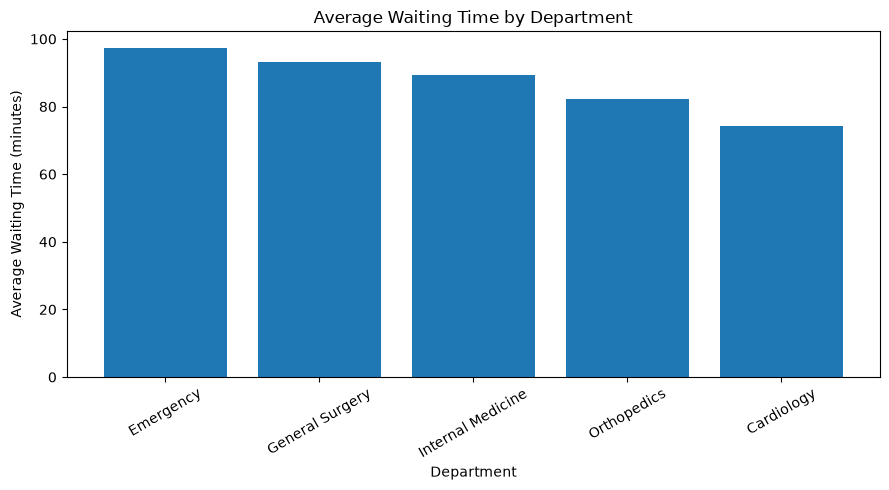

In [53]:
plt.figure(figsize=(9, 5))

plt.bar(
    waiting_by_dept.index,
    waiting_by_dept.values
)

plt.title("Average Waiting Time by Department")
plt.xlabel("Department")
plt.ylabel("Average Waiting Time (minutes)")

plt.xticks(rotation=30)
plt.savefig("waiting_time_by_department.png", dpi=300)
plt.tight_layout()
plt.show()

In [59]:
waiting_by_type = (
    df_clean.groupby("admission_type")["waiting_time_min"]
    .mean()
)
print(waiting_by_type)

admission_type
Routine    86.404494
Urgent     93.426471
Name: waiting_time_min, dtype: float64


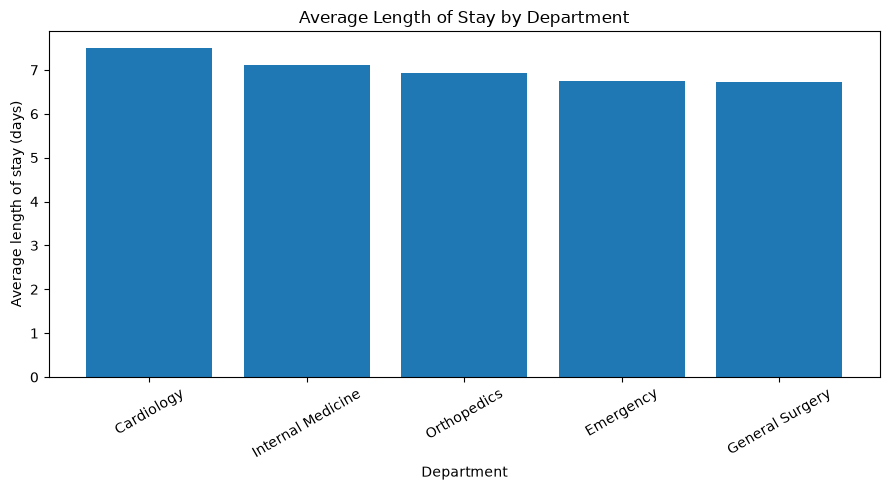

In [65]:
import matplotlib.pyplot as plt

los_by_dept = (
    df_clean.groupby("department")["length_of_stay_days"]
    .mean()
    .sort_values(ascending= False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    los_by_dept.index,
    los_by_dept.values
)

plt.title("Average Length of Stay by Department")
plt.xlabel("Department")
plt.ylabel("Average length of stay (days)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("length_of_stay_by_department.png", dpi=300)
plt.show()

Operational Performance Analysis

In [67]:
slowest_department = waiting_by_dept.idxmax()
highest_waiting_time = waiting_by_dept.max()

print(slowest_department)
print(highest_waiting_time)

Emergency
97.38095238095238


In [73]:
#Performance Gap
waiting_gap = waiting_by_dept.max()-waiting_by_dept.min()
print(round(waiting_gap,2))

23.23


In [74]:
long_waits = df_clean["waiting_time_min"]> 120
long_wait_percentage = long_waits.mean() * 100
print(round(long_wait_percentage, 2))

31.87


Analyze peak-hour patient volumes, staffing levels, and patient flow in the Emergency Department to identify potential bottlenecks and opportunities to reduce waiting times.